# License Plate Detection + OCR + CSV
### YOLOv8n Fine-tuning • EasyOCR • Kaggle

## 1. Install Packages

In [1]:
!pip install -q ultralytics easyocr pyyaml


## 2. Import Libraries

In [2]:
import os
import re
import random
import shutil
from pathlib import Path

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import easyocr

from ultralytics import YOLO
from IPython.display import FileLink, display


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 3. Check GPU

In [3]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    DEVICE = "cpu"
    print("GPU is not enabled.")


CUDA available: True
GPU: Tesla T4


## 4. Define Dataset Paths

In [4]:
# Kaggle dataset from: fareselmenshawii/license-plate-dataset
DATASET_ROOT = "/kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset"

CANDIDATE_LAYOUTS = [
    (
        f"{DATASET_ROOT}/images/train", f"{DATASET_ROOT}/labels/train",
        f"{DATASET_ROOT}/images/val", f"{DATASET_ROOT}/labels/val"
    ),
    (
        f"{DATASET_ROOT}/train/images", f"{DATASET_ROOT}/train/labels",
        f"{DATASET_ROOT}/val/images", f"{DATASET_ROOT}/val/labels"
    ),
    (
        f"{DATASET_ROOT}/license-plate-dataset/images/train",
        f"{DATASET_ROOT}/license-plate-dataset/labels/train",
        f"{DATASET_ROOT}/license-plate-dataset/images/val",
        f"{DATASET_ROOT}/license-plate-dataset/labels/val"
    ),
]

TRAIN_IMAGES = TRAIN_LABELS = VAL_IMAGES = VAL_LABELS = None

for train_img, train_lbl, val_img, val_lbl in CANDIDATE_LAYOUTS:
    if all(os.path.isdir(path) for path in (train_img, train_lbl, val_img, val_lbl)):
        TRAIN_IMAGES, TRAIN_LABELS = train_img, train_lbl
        VAL_IMAGES, VAL_LABELS = val_img, val_lbl
        break

if TRAIN_IMAGES is None:
    raise FileNotFoundError(
        f"Dataset folders not found under {DATASET_ROOT}. "
        "Check the dataset path and folder layout."
    )

print("Training images:", TRAIN_IMAGES)
print("Training labels:", TRAIN_LABELS)
print("Validation images:", VAL_IMAGES)
print("Validation labels:", VAL_LABELS)


Training images: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/images/train
Training labels: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/labels/train
Validation images: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/images/val
Validation labels: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/labels/val


## 5. Check Dataset Folders

In [5]:
print("Train images exists:", os.path.exists(TRAIN_IMAGES))
print("Train labels exists:", os.path.exists(TRAIN_LABELS))

print("Val images exists:", os.path.exists(VAL_IMAGES))
print("Val labels exists:", os.path.exists(VAL_LABELS))


Train images exists: True
Train labels exists: True
Val images exists: True
Val labels exists: True


## 6. Count Images and Labels

In [6]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

train_images = [
    p
    for p in Path(TRAIN_IMAGES).glob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

train_labels = list(
    Path(TRAIN_LABELS).glob("*.txt")
)

val_images = [
    p
    for p in Path(VAL_IMAGES).glob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

val_labels = list(
    Path(VAL_LABELS).glob("*.txt")
)

print("Training Images:", len(train_images))
print("Training Labels:", len(train_labels))

print("Validation Images:", len(val_images))
print("Validation Labels:", len(val_labels))

if not train_images or not val_images or not train_labels:
    raise RuntimeError("Training/validation images or training labels are missing.")


Training Images: 25470
Training Labels: 25470
Validation Images: 1073
Validation Labels: 1073


## 7. Inspect One YOLO Label

In [7]:
example_label = train_labels[0]

print("Label file:", example_label)

with open(example_label, "r") as file:
    print(file.read())


Label file: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/labels/train/00009e5b390986a0.txt
0 0.4805078125 0.8983397565982405 0.04124999999999995 0.030018999999999924
0 0.9905859375 0.7705236539589442 0.01375000000000004 0.018762000000000074



## 8. Create data.yaml

In [8]:
DATA_YAML = "/kaggle/working/data.yaml"

data = {
    "train": TRAIN_IMAGES,
    "val": VAL_IMAGES,
    "nc": 1,
    "names": {0: "license_plate"},
}

with open(DATA_YAML, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

print(Path(DATA_YAML).read_text())


train: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/images/train
val: /kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/images/val
nc: 1
names:
  0: license_plate



## 9. Show One Training Image

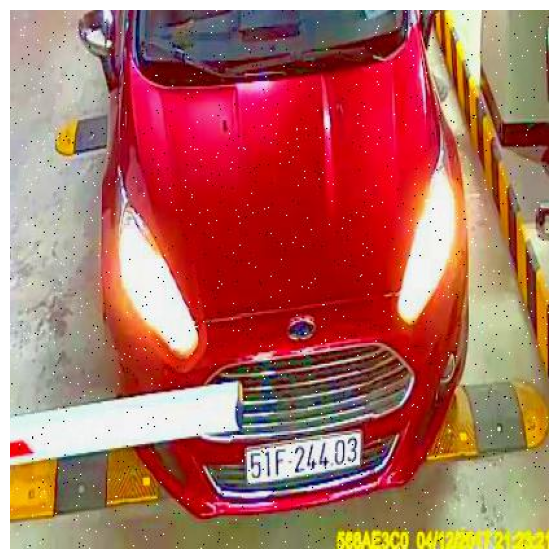

/kaggle/input/datasets/fareselmenshawii/large-license-plate-dataset/images/train/CarLongPlateGen1172_jpg.rf.6b2f65eb302b0eff6becd5d657ff7e19.jpg


In [9]:
TRAIN_SAMPLE = str(
    random.choice(train_images)
)

image = cv2.imread(TRAIN_SAMPLE)

plt.figure(figsize=(12, 7))

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()

print(TRAIN_SAMPLE)


## 10. Load Pretrained YOLOv8n

In [10]:
model = YOLO("yolov8n.pt")

print("YOLOv8n loaded.")


YOLOv8n loaded.


## 11. Fine-tune YOLOv8n

In [ ]:
results = model.train(
    data=DATA_YAML,
    epochs=25,
    imgsz=640,
    batch=16,
    device=DEVICE,
    workers=2,
    patience=15,
    project="/kaggle/working/runs/detect",
    name="license_plate_yolov8",
    exist_ok=True
)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=license_plate_yolov8, nbs=64, nms=None, opset=None, optimize=Fa

## 12. Save Best Fine-tuned Model

In [ ]:
BEST_MODEL = "/kaggle/working/runs/detect/license_plate_yolov8/weights/best.pt"
SAVED_MODEL = "/kaggle/working/license_plate_best.pt"

if not Path(BEST_MODEL).is_file():
    raise FileNotFoundError(f"Trained checkpoint not found: {BEST_MODEL}")

shutil.copy2(BEST_MODEL, SAVED_MODEL)
print("Saved fine-tuned model:", SAVED_MODEL)


## 13. Load Best Model Once

In [ ]:
# Use this fine-tuned model for validation, images, and video OCR.
# The OCR section below REUSES best_model rather than loading it again.
best_model = YOLO(SAVED_MODEL)
print("Fine-tuned model loaded:", SAVED_MODEL)


## 14. Validate Fine-tuned Model

In [ ]:
metrics = best_model.val(
    data=DATA_YAML,
    imgsz=640,
    device=DEVICE
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)


## 15. Choose One Validation Image

In [ ]:
TEST_IMAGE = str(
    random.choice(val_images)
)

print("Validation image:", TEST_IMAGE)

image = cv2.imread(TEST_IMAGE)

plt.figure(figsize=(12, 7))

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()


## 16. Detect License Plate in Image

In [ ]:
results = best_model.predict(
    source=TEST_IMAGE,
    conf=0.5,
    device=DEVICE,
    verbose=False
)

annotated_image = results[0].plot()

plt.figure(figsize=(12, 7))

plt.imshow(
    cv2.cvtColor(
        annotated_image,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()


## 17. Load EasyOCR and Set Video Paths

In [ ]:
# Reuse best_model from section 13; no second checkpoint load.
VIDEO_PATH = "/kaggle/input/datasets/anandarimal/video1234/video.mp4"
OUTPUT_VIDEO = "/kaggle/working/license_plate_output.mp4"
OUTPUT_CSV = "/kaggle/working/license_plates.csv"
UNIQUE_CSV = "/kaggle/working/unique_license_plates.csv"

if not Path(VIDEO_PATH).is_file():
    raise FileNotFoundError(f"Input video not found: {VIDEO_PATH}")

reader = easyocr.Reader(
    ["en"],
    gpu=torch.cuda.is_available()
)

print("Using fine-tuned YOLOv8 model for detection")
print("EasyOCR ready")
print("Input video:", VIDEO_PATH)


## 18. Preprocess License Plate and Read Text

In [ ]:
def clean_text(text):
    return re.sub(r"[^A-Z0-9]", "", text.upper())


def read_license_plate(crop):

    if crop is None or crop.size == 0:
        return "", 0.0

    # Resize
    crop = cv2.resize(
        crop, None,
        fx=3, fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Grayscale
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

    # Contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    gray = clahe.apply(gray)

    # Noise reduction
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Threshold
    _, threshold = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    best_text = ""
    best_confidence = 0.0

    # OCR on both processed images
    for image in [gray, threshold]:

        results = reader.readtext(
            image,
            detail=1,
            paragraph=False,
            allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
        )

        if not results:
            continue

        # Combine text regions from left to right
        results = sorted(
            results,
            key=lambda x: x[0][0][0]
        )

        text = clean_text(
            "".join(r[1] for r in results)
        )

        confidence = sum(
            float(r[2]) for r in results
        ) / len(results)

        if text and confidence > best_confidence:
            best_text = text
            best_confidence = confidence

    return best_text, best_confidence


## 19. Detect Plates and Apply OCR

In [ ]:
def process_frame(frame, frame_number=0, fps=25):

    annotated = frame.copy()
    records = []

    # YOLO detection
    results = best_model.predict(
        frame,
        conf=0.40,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )[0]

    height, width = frame.shape[:2]

    for box in results.boxes:

        # Bounding box coordinates
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        # Padding
        padding = 5

        x1 = max(0, x1 - padding)
        y1 = max(0, y1 - padding)
        x2 = min(width, x2 + padding)
        y2 = min(height, y2 + padding)

        if x2 <= x1 or y2 <= y1:
            continue

        # YOLO confidence
        yolo_conf = float(box.conf[0])

        # Crop license plate
        plate_crop = frame[y1:y2, x1:x2]

        # OCR recognition
        plate_text, ocr_conf = read_license_plate(
            plate_crop
        )

        # Draw bounding box
        cv2.rectangle(
            annotated,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Display recognized text
        label = (
            f"{plate_text} OCR:{ocr_conf:.2f}"
            if plate_text
            else f"Plate {yolo_conf:.2f}"
        )

        cv2.putText(
            annotated,
            label,
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        # Store result
        records.append({
            "frame": frame_number,
            "time_seconds": round(frame_number / fps, 2),
            "plate_text": plate_text,
            "yolo_confidence": round(yolo_conf, 3),
            "ocr_confidence": round(ocr_conf, 3),
            "status": "READ" if plate_text else "NOT_READ"
        })

    return annotated, records


## 20. Test Detection + OCR on One Frame

In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Could not read the first video frame")

annotated, records = process_frame(frame)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8 License Plate Detection + EasyOCR")
plt.axis("off")
plt.show()

print("Detections:", len(records))
for record in records:
    print(f"Plate: {record['plate_text']} | OCR confidence: {record['ocr_confidence']}")


## 21. Process Complete Video

In [ ]:
# Open video
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open video")

# Video properties
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 25

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Output video
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video")

all_records = []
frame_number = 0

try:
    while True:

        success, frame = cap.read()

        if not success:
            break

        # Detect license plates + OCR
        annotated, records = process_frame(
            frame,
            frame_number=frame_number,
            fps=fps
        )

        # Save processed frame
        writer.write(annotated)

        # Store detections
        all_records.extend(records)

        frame_number += 1

        # Progress
        if frame_number % 50 == 0:
            print(
                f"Processed {frame_number}/{total_frames} frames"
            )

finally:
    cap.release()
    writer.release()

print("Processing completed")
print("Frames:", frame_number)
print("Detections:", len(all_records))
print("Video saved:", OUTPUT_VIDEO)


## 22. Save Detected License Plates to CSV

In [ ]:
columns = [
    "frame", "time_seconds", "plate_text",
    "yolo_confidence", "ocr_confidence", "status"
]

# Save every detection, including plates for which OCR returned no text.
df = pd.DataFrame(all_records, columns=columns)
df.to_csv(OUTPUT_CSV, index=False)

# Remove duplicate OCR strings (not necessarily duplicate vehicles).
unique_plates = (
    df.loc[df["plate_text"].notna() & (df["plate_text"] != ""), ["plate_text"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .rename(columns={"plate_text": "license_plate"})
)
unique_plates.to_csv(UNIQUE_CSV, index=False)

print("Total detections:", len(df))
print("Nonempty OCR strings:", (df["status"] == "READ").sum())
print("Distinct OCR strings:", len(unique_plates))

display(df.head(20))
display(unique_plates.head(20))

# Kaggle links to generated outputs
display(FileLink(OUTPUT_VIDEO))
display(FileLink(OUTPUT_CSV))
display(FileLink(UNIQUE_CSV))
